# Why does the fitted coherence field stay flat? (Study 9, ZOIB)

In both the stationary and amplitude ZOIB fits, the ratings-free coherence pz1 barely changes across conditions (0.80–0.86). So the predicted condition effects are about 0.003, while the data's are about 0.05 (SD across conditions × features). This notebook asks why the marginal likelihood prefers that flat field.

**Split of log Z.** `total_log_lik_zoib` scores the generics as data as well as the ratings:

  log Z = log p(generics | θ) + log p(ratings | generics, θ)

The first term is the ratings-free Laplace log Z. All 60 statements are generics, so a high μ₀ makes them likely a priori, which is pure bookkeeping. The second term is the part that measures fit to the ratings.

**Grid:** ℓ = 0.344 (fitted), σ₀ ∈ {0.52, 1, 2, 3}, μ₀ ∈ {−1, 0, 1.29}, β ∈ {3, 25.9}. At each point the ZOIB linking is re-profiled, as in the fit. For each θ:
- **pz1_range:** the median, over features, of the range of ratings-free pz1 across the 4 conditions. This is how much the field moves.
- **pred_eff_sd** and **emp_eff_sd:** the SD of condition effects (rating minus that feature's mean over conditions), predicted vs empirical.
- **r_eff:** the correlation between predicted and empirical condition effects (60 values, 4 conditions × 15 features). This measures whether the field moves the *right* features.

In [1]:
import os, sys, time
os.environ.setdefault("JAX_ENABLE_X64", "1"); sys.path.insert(0, '.')
import numpy as np, pandas as pd, jax.numpy as jnp
import matplotlib.pyplot as plt
import inference as inf, linking as lk
import plot_style; plot_style.use_lexend()

geom = inf.load_geometry(); J = geom['J']; TRAIT = np.array(geom['test_trait']); CATS = ['physical', 'diet', 'personality']
R, _ = inf.load_responses('../../data/study9_prereg.csv', clip_interior=False)
emp = np.array([np.asarray(R[c]).mean(0) for c in inf.CONDITIONS])     # (4 conditions, J)
emp_eff = emp - emp.mean(0)
free = inf._ratings_free_cond_data(geom)

def evaluate(ls, mu0, sig, beta, return_pred=False):
    ll, link_theta, _ = inf.total_log_lik_zoib(geom, R, ls, mu0, sig, beta_speaker=beta, return_link=True)
    ll_u = sum(inf.laplace_log_Z(free[c], ls, mu0, sig, beta)[0] for c in inf.CONDITIONS)
    pz = inf.prior_pz1_modes(geom, ls, mu0, sig, beta)
    p = lk.unpack(jnp.asarray(link_theta))
    pred = np.array([np.asarray(lk.expected_rating(p, pz[c])) for c in inf.CONDITIONS])
    pred_eff = pred - pred.mean(0)
    pzm = np.array([pz[c] for c in inf.CONDITIONS])
    row = dict(ls=ls, mu0=mu0, sig=sig, beta=beta, logZ=ll, log_p_u=ll_u, log_p_r_given_u=ll - ll_u,
               pz1_range=float(np.median(np.ptp(pzm, 0))), pred_eff_sd=float(pred_eff.std()),
               emp_eff_sd=float(emp_eff.std()), r_eff=float(np.corrcoef(pred_eff.ravel(), emp_eff.ravel())[0, 1]))
    return (row, pred) if return_pred else row

FIT = (0.344, 1.293, 0.522, 25.93)
rows = [evaluate(*FIT)]
for sig in [0.522, 1.0, 2.0, 3.0]:
    for mu0 in [-1.0, 0.0, 1.293]:
        for beta in [3.0, 25.93]:
            if (mu0, sig, beta) != FIT[1:]:          # the fitted point is already row 0
                rows.append(evaluate(0.344, mu0, sig, beta))
grid = pd.DataFrame(rows)
fit = grid.iloc[0]
grid['Δ log p(u)'] = grid.log_p_u - fit.log_p_u
grid['Δ log p(r|u)'] = grid.log_p_r_given_u - fit.log_p_r_given_u
pd.set_option('display.width', 220)
grid.round(3)

,ls,mu0,sig,beta,logZ,log_p_u,log_p_r_given_u,pz1_range,pred_eff_sd,emp_eff_sd,r_eff,Δ log p(u),Δ log p(r|u)
0,0.344,1.293,0.522,25.93,-1719.894,-15.253,-1704.641,0.035,0.003,0.049,0.343,0.000,0.000
1,0.344,-1.000,0.522,3.00,-1802.750,-52.517,-1750.233,0.159,0.017,0.049,0.418,-37.264,-45.592
2,0.344,-1.000,0.522,25.93,-1804.940,-50.457,-1754.482,0.217,0.021,0.049,0.431,-35.204,-49.842
3,0.344,0.000,0.522,3.00,-1795.092,-38.843,-1756.249,0.080,0.008,0.049,0.363,-23.591,-51.608
4,0.344,0.000,0.522,25.93,-1764.378,-30.087,-1734.291,0.136,0.012,0.049,0.407,-14.834,-29.650
5,0.344,1.293,0.522,3.00,-1741.120,-33.170,-1707.950,0.005,0.000,0.049,-0.361,-17.917,-3.309
6,0.344,-1.000,1.000,3.00,-1806.422,-44.699,-1761.723,0.243,0.022,0.049,0.356,-29.446,-57.082
7,0.344,-1.000,1.000,25.93,-1785.140,-32.711,-1752.430,0.328,0.026,0.049,0.371,-17.458,-47.789
8,0.344,0.000,1.000,3.00,-1777.833,-38.260,-1739.573,0.120,0.013,0.049,0.316,-23.007,-34.932
9,0.344,0.000,1.000,25.93,-1742.971,-23.176,-1719.795,0.187,0.016,0.049,0.335,-7.924,-15.154


**What this shows:**
- **It's not just bookkeeping.** At the fitted θ (row 0), *both* parts are the best on the grid. log p(generics | θ) is highest there, at −15, but so is log p(ratings | generics, θ). Every other θ on the grid is worse on the **ratings** term too, by about 3 to 57 log units.
- **No θ on the grid gets condition effects to the right size.** The predicted SD grows roughly in proportion to how much the field moves, but it tops out at about 0.026 (pz1 range 0.33), against 0.049 in the data. Matching the data's size would take a field moving about twice as much as anything on this grid.
- **Where the field moves, it moves the wrong features.** r_eff is only about 0.2–0.6. So the ratings likelihood pays for a moving field (the ratings don't follow its pattern) and gains little, and the fit settles on the flattest field it can.

## Which pattern is the field missing?

Condition × category tables of mean condition effects (rating minus that feature's mean over the four conditions), for the data, the fitted θ, and the θ on the grid with the highest r_eff.

In [2]:
best = grid.iloc[grid.r_eff.idxmax()]
def cat_table(eff):
    return pd.DataFrame([[eff[k][TRAIT == t].mean() for t in CATS] for k in range(4)],
                        index=[f'{c} cond' for c in inf.CONDITIONS], columns=CATS)
print('data:'); print(cat_table(emp_eff).round(3).to_string())
for name, th in [('fitted θ', FIT), (f"best-r θ (mu0={best.mu0:g}, sigma={best.sig:g}, beta={best.beta:g})",
                                      (best.ls, best.mu0, best.sig, best.beta))]:
    _, pred = evaluate(*th, return_pred=True)
    print(f'\n{name}:'); print(cat_table(pred - pred.mean(0)).round(3).to_string())

data:
                    physical   diet  personality
physical cond          0.092  0.051        0.024
diet cond             -0.028  0.029       -0.015
personality cond      -0.029 -0.033        0.034
heterogeneous cond    -0.035 -0.047       -0.042



fitted θ:
                    physical   diet  personality
physical cond          0.004 -0.003       -0.002
diet cond             -0.004  0.004       -0.002
personality cond      -0.001 -0.003        0.003
heterogeneous cond     0.001  0.001        0.001



best-r θ (mu0=-1, sigma=2, beta=3):
                    physical   diet  personality
physical cond          0.045 -0.009        0.001
diet cond             -0.038  0.019       -0.013
personality cond       0.002 -0.010        0.027
heterogeneous cond    -0.009 -0.001       -0.016


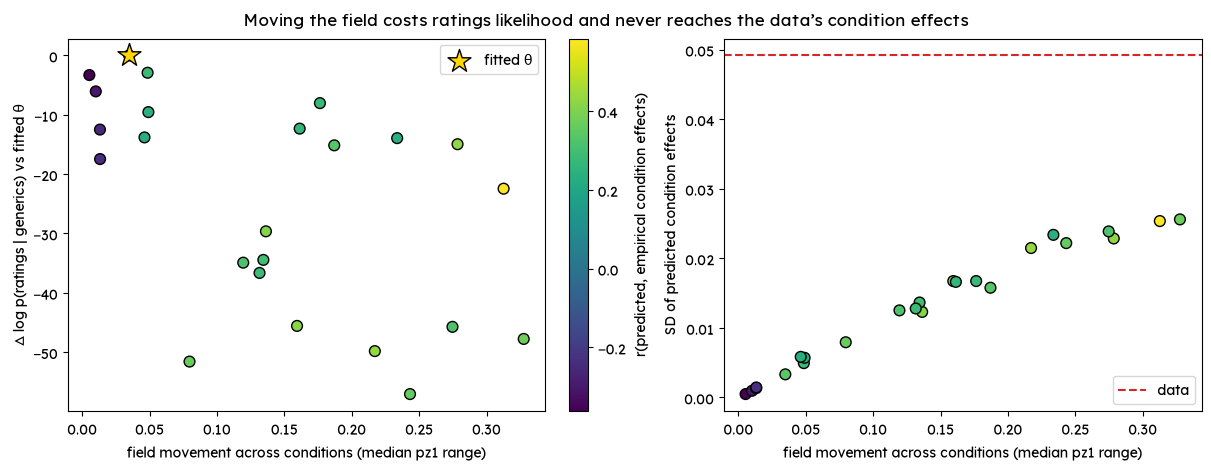

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
sc = axes[0].scatter(grid.pz1_range, grid['Δ log p(r|u)'], c=grid.r_eff, cmap='viridis', s=60, edgecolor='k')
axes[0].scatter([fit.pz1_range], [0], marker='*', s=300, c='gold', edgecolor='k', zorder=3, label='fitted θ')
axes[0].set_xlabel('field movement across conditions (median pz1 range)'); axes[0].set_ylabel('Δ log p(ratings | generics) vs fitted θ')
axes[0].legend(); fig.colorbar(sc, ax=axes[0], label='r(predicted, empirical condition effects)')
axes[1].scatter(grid.pz1_range, grid.pred_eff_sd, c=grid.r_eff, cmap='viridis', s=60, edgecolor='k')
axes[1].axhline(grid.emp_eff_sd.iloc[0], color='tab:red', ls='--', label='data')
axes[1].set_xlabel('field movement across conditions (median pz1 range)'); axes[1].set_ylabel('SD of predicted condition effects')
axes[1].legend()
fig.suptitle('Moving the field costs ratings likelihood and never reaches the data’s condition effects')
plt.show()

**What the tables show:** effects are relative to each feature's mean over all four conditions, so the heterogeneous row is included this time.
- **Even the best-matching θ only gets the diagonal right.** With μ₀ = −1, σ₀ = 2 and β = 3, each condition's own category goes up, as in the data (physical 0.045 vs 0.092). It misses **both** of the data's other signatures:
  1. **Physical generics spreading to diet and personality:** 0.051 and 0.024 in the data, against −0.009 and 0.001 here.
  2. **The heterogeneous condition being the lowest for every category:** −0.035 to −0.047 in the data, against about −0.01 here. Hearing generics about features from all three categories lowers ratings *everywhere*, relative to hearing generics about one category.
- **The second point is new, and the model has no mechanism for it.** Heterogeneous participants hear the same number of generics, but spread across the space. Note also that `asymmetry-sim-check.ipynb` used the heterogeneous condition as its baseline. It's actually the lowest condition, so that baseline makes every shift look somewhat larger than it would against a neutral one.

## Takeaway

The field is flat because a **distance-based, symmetric** field can't produce the condition pattern in the ratings. In the data, physical generics raise everything, and diet and personality generics raise only their own category (see `asymmetry-sim-check.ipynb`). Any θ that lets the field move spreads generics the wrong way, so the ratings likelihood rewards keeping it flat, and the per-feature linking then carries the feature differences. This is the same mismatch as in the asymmetry analysis, seen from the fitting side: the missing ingredient is a **train-side** asymmetry (see the deferred prior-mean plan), not more flexibility in the kernel.

Caveat: this grid holds ℓ fixed at 0.344, and the generic-free ratings likelihood depends on the profiled linking.